
- [ ] definir arquitectura de la red.
- [ ] Implementar el mecanismo para guardar y sacar experiencias pasadas. (replay buffer)

La red será action-out: le damos un estado y devuelve los valores para las tres acciones.
Necesitamos cubrir todos los negativos así que utilizaremos una función de activación lineal.

El replay buffer será un double-ended queue:Si fijo un tamaño máximo y sigo agregando elementos, descarta los más viejos
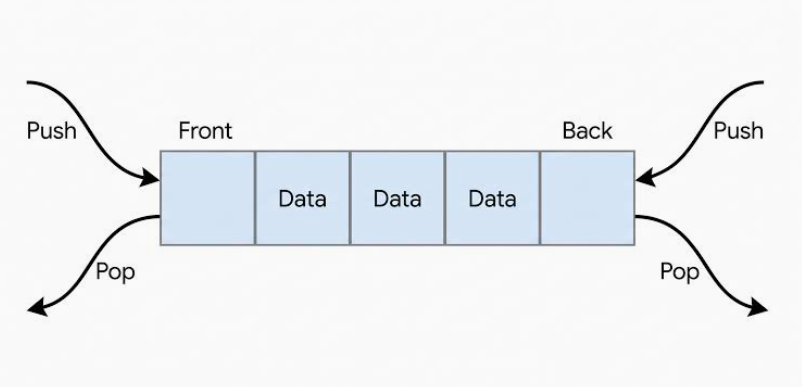

deque() sirve para descartar lo más viejo en O(1)

In [58]:
#!pip install torch


In [ ]:

import torch
import torch.nn as nn
import numpy as np
import random
from collections import deque
import gymnasium as gym
import matplotlib.pyplot as plt
import IPython 
import numpy as np

In [ ]:
semilla=45
torch.manual_seed(semilla)
random.seed(semilla)

In [ ]:
class ReplayBuffer:
    # Vuelve a "reproducir" la experiencia pero mezclada
    # Conviene porque descenso por el gradiente espera datos iid.
    def __init__(self,capacidad):
        #crea la estructura de datos
        
        self.memoria=  deque(maxlen=capacidad)

        
        
    def add(self,s,a,r,s_prima,done):
        # guarda una transición en el buffer.
        # Cada vez que el agente da un paso en el entorno, obtiene (s,a,r,s_prima,done)
        
        self.memoria.append((s,a,r,s_prima,done))
    def sample(self,batch_size):
        #elegir batch_size transiciones al azar (sin repetir dentro del batch?) random.sample
        #transponer

        indices=sorted(random.sample(range(0,len(self.memoria)),batch_size))
        sampleo=[self.memoria[i] for i in indices]
        estados,acciones,rewards,estados_siguientes,terminaciones=zip(*sampleo) #-> grupo de 64 estados, cada uno un array de 6 elem , grupo de 64 acciones, cada una un array de 1 elem
        estados=torch.tensor(np.stack(estados),dtype=torch.float32) #-> único array de la forma (64,6)
        acciones=torch.tensor(np.array(acciones),dtype=torch.int64) #-> único array de la forma (64,)
        rewards=torch.tensor(np.array(rewards),dtype=torch.float32) #-> único array de la forma (64,)
        estados_siguientes=torch.tensor(np.stack(estados_siguientes),dtype=torch.float32) #-> único array de la forma (64,6)
        terminaciones=torch.tensor(np.array(terminaciones),dtype=torch.float32)#-> único array de la forma (64,)
        
        
        return estados,acciones,rewards,estados_siguientes,terminaciones

In [62]:
class DeepQNetwork(torch.nn.Module):
    #nn.Module es la clase base de toda red en Pytorch. 
    # Cuando defino capas como nn.Linear dentro de tu clase, nn.Module las registra automáticamente y sabe cuáles son sus parámetros entrenables
    # Poe eso después podés pedirle todos lso pesos de una sola vez para pasárselos al optimizador, moverla de CPU a GPU, guardarla o cargarla, o ponerla en modo evaluación
    
    def __init__(self,env):
        super().__init__() # llama al init de la clase que heredamos, en este caso nn.Module
  
        self.network= nn.Sequential(
            nn.Linear(env.observation_space.shape[0],120),
            nn.ReLU(),
            nn.Linear(120,84),
            nn.ReLU(),
            nn.Linear(84,env.action_space.n)
            # no tiene función de activación: al principio puede devolver negativo,
            # pero esperamos que luego se corrija.
        )
    def forward(self,x):
        # x es un batch de estados
        return self.network(x)

env= gym.make("Acrobot-v1", render_mode="rgb_array")
env.reset(seed=semilla,options={"low":-0.1,"high":0.1})

red= DeepQNetwork(env)
# llamar a red() hace lo mismo pero es más pro que llamar a forward() 
red(torch.zeros(64,6))

tensor([[ 0.0767, -0.1132,  0.1165],
        [ 0.0767, -0.1132,  0.1165],
        [ 0.0767, -0.1132,  0.1165],
        [ 0.0767, -0.1132,  0.1165],
        [ 0.0767, -0.1132,  0.1165],
        [ 0.0767, -0.1132,  0.1165],
        [ 0.0767, -0.1132,  0.1165],
        [ 0.0767, -0.1132,  0.1165],
        [ 0.0767, -0.1132,  0.1165],
        [ 0.0767, -0.1132,  0.1165],
        [ 0.0767, -0.1132,  0.1165],
        [ 0.0767, -0.1132,  0.1165],
        [ 0.0767, -0.1132,  0.1165],
        [ 0.0767, -0.1132,  0.1165],
        [ 0.0767, -0.1132,  0.1165],
        [ 0.0767, -0.1132,  0.1165],
        [ 0.0767, -0.1132,  0.1165],
        [ 0.0767, -0.1132,  0.1165],
        [ 0.0767, -0.1132,  0.1165],
        [ 0.0767, -0.1132,  0.1165],
        [ 0.0767, -0.1132,  0.1165],
        [ 0.0767, -0.1132,  0.1165],
        [ 0.0767, -0.1132,  0.1165],
        [ 0.0767, -0.1132,  0.1165],
        [ 0.0767, -0.1132,  0.1165],
        [ 0.0767, -0.1132,  0.1165],
        [ 0.0767, -0.1132,  0.1165],
 

Probar el replay buffer con datos generados mediante una política al azar.

In [63]:
def transiciones_azar(semilla,Nrep,rb):
    """
    Nrep es la cantidad de episodios que querés que ocurran

    Llena el buffer con transiciones al azar.
    """
    env= gym.make("Acrobot-v1")
    observation, info = env.reset(seed=semilla)
    env.action_space.seed(semilla)

    for i in range(Nrep):
        observation, info = env.reset()
        truncated=False
        terminated= False

        retorno_acum=0
        N_pasos=0
        while not (terminated or truncated):
            # this is where you would insert your policy
            action = env.action_space.sample()
            s=observation
            # step (transition) through the environment with the action
            # receiving the next observation, reward and if the episode has terminated or truncated
            observation, reward, terminated, truncated, info = env.step( action) 

            
            
            rb.add(s,action,reward,observation,terminated)
            

    env.close()
 
buffer=ReplayBuffer(1000)
 
len(buffer.memoria)
transiciones_azar(semilla,1,buffer)
len(buffer.memoria)

500